# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Student Performance Dataset](https://www.kaggle.com/datasets/bornaetminan/student-performance-clean-and-mldl-ready?select=student_performance_clean.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('student_performance_clean.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23.0,84.0,Low,High,No,7.0,73.0,Low,Yes,0.0,Low,Medium,Public,Positive,3.0,No,High School,Near,Male,67.0
1,19.0,64.0,Low,Medium,No,8.0,59.0,Low,Yes,2.0,Medium,Medium,Public,Negative,4.0,No,College,Moderate,Female,61.0
2,24.0,98.0,Medium,Medium,Yes,7.0,91.0,Medium,Yes,2.0,Medium,Medium,Public,Neutral,4.0,No,Postgraduate,Near,Male,74.0
3,18.0,89.0,Low,Medium,Yes,8.0,98.0,Medium,Yes,1.0,Medium,Medium,Public,Negative,4.0,No,High School,Moderate,Male,71.0
4,19.0,92.0,Medium,Medium,Yes,6.0,65.0,Medium,Yes,3.0,Medium,High,Public,Neutral,4.0,No,College,Near,Female,70.0


## last Five row

In [4]:
df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,18.0,69.0,High,Medium,No,7.0,76.0,Medium,Yes,1.0,High,Medium,Public,Positive,2.0,No,High School,Near,Female,68.0
6603,23.0,76.0,High,Medium,No,8.0,81.0,Medium,Yes,3.0,Low,High,Public,Positive,2.0,No,High School,Near,Female,69.0
6604,20.0,90.0,Medium,Low,Yes,6.0,65.0,Low,Yes,3.0,Low,Medium,Public,Negative,2.0,No,Postgraduate,Near,Female,68.0
6605,10.0,86.0,High,High,Yes,6.0,91.0,High,Yes,2.0,Low,Medium,Private,Positive,3.0,No,High School,Far,Female,68.0
6606,15.0,67.0,Medium,Low,Yes,9.0,94.0,Medium,Yes,0.0,Medium,Medium,Public,Positive,4.0,No,Postgraduate,Near,Male,64.0


## Shape of our dataset

In [5]:
df.shape

(6607, 20)

## List out all columns

In [6]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Hours_Studied                 float64
Attendance                    float64
Parental_Involvement           object
Access_to_Resources            object
Extracurricular_Activities     object
Sleep_Hours                   float64
Previous_Scores               float64
Motivation_Level               object
Internet_Access                object
Tutoring_Sessions             float64
Family_Income                  object
Teacher_Quality                object
School_Type                    object
Peer_Influence                 object
Physical_Activity             float64
Learning_Disabilities          object
Parental_Education_Level       object
Distance_from_Home             object
Gender                         object
Exam_Score                    float64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Hours_Studied               6607 non-null   float64
 1   Attendance                  6607 non-null   float64
 2   Parental_Involvement        6607 non-null   object 
 3   Access_to_Resources         6607 non-null   object 
 4   Extracurricular_Activities  6607 non-null   object 
 5   Sleep_Hours                 6607 non-null   float64
 6   Previous_Scores             6607 non-null   float64
 7   Motivation_Level            6607 non-null   object 
 8   Internet_Access             6607 non-null   object 
 9   Tutoring_Sessions           6607 non-null   float64
 10  Family_Income               6607 non-null   object 
 11  Teacher_Quality             6607 non-null   object 
 12  School_Type                 6607 non-null   object 
 13  Peer_Influence              6607 

## Check Null Value

In [9]:
df.isnull().sum()

Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,17.756622,79.977448,7.02906,75.070531,1.493719,2.967610,67.230513
std,3.951964,11.547475,1.46812,14.399784,1.230570,1.031231,3.868211
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,18.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,20.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,24.000000,100.000000,10.00000,100.000000,8.000000,6.000000,100.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

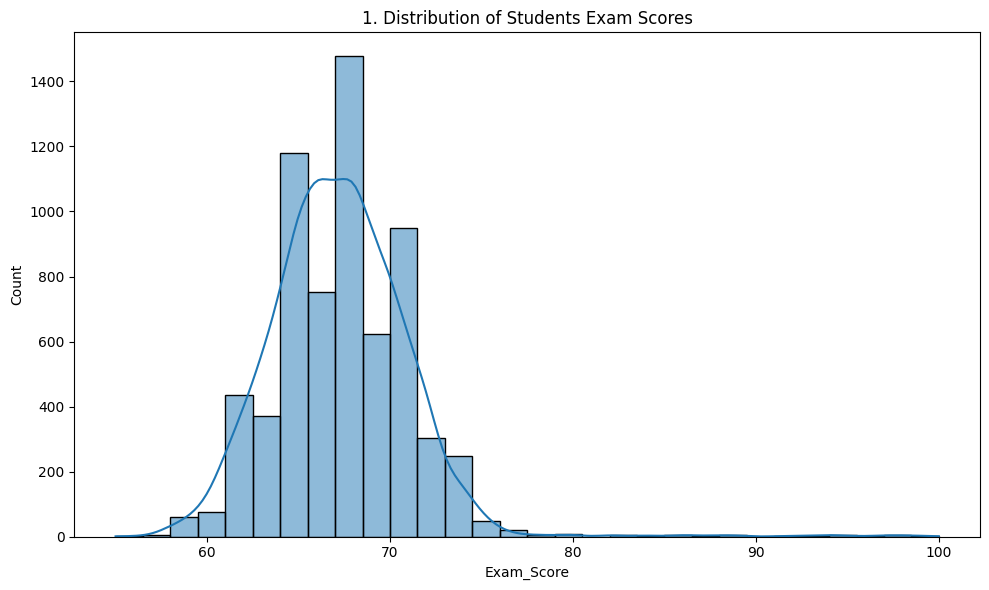

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Exam_Score', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Students Exam Scores')
show_fig()
plot_no += 1

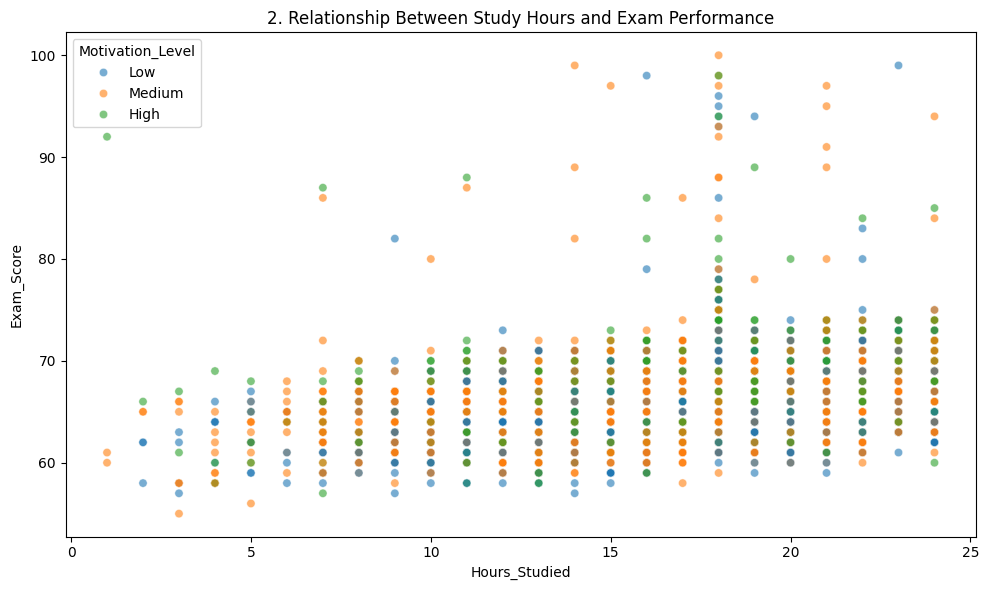

In [14]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Hours_Studied', y='Exam_Score', hue='Motivation_Level', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Study Hours and Exam Performance')
show_fig()
plot_no += 1

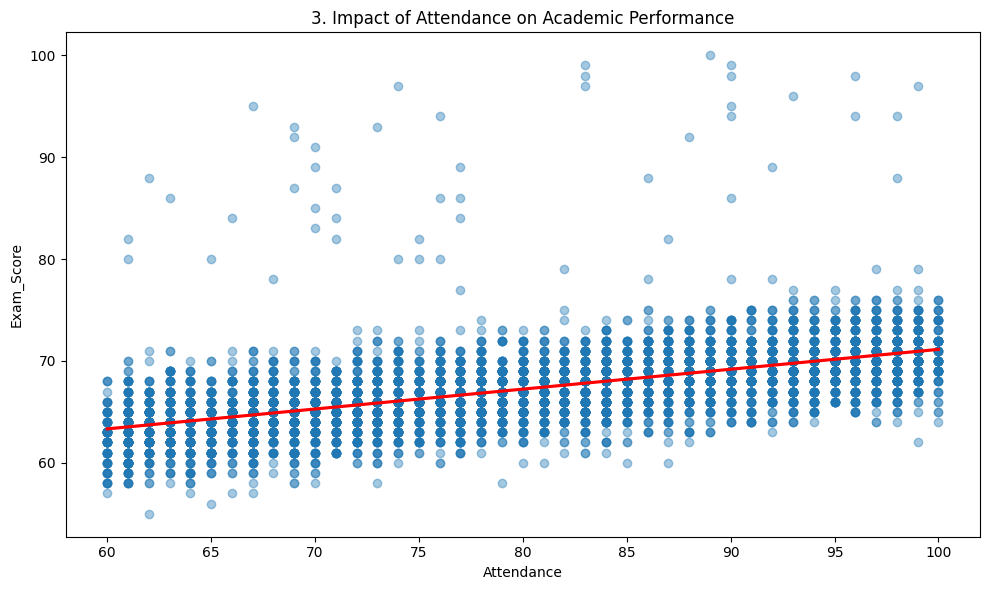

In [15]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Attendance', y='Exam_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Impact of Attendance on Academic Performance')
show_fig()
plot_no += 1

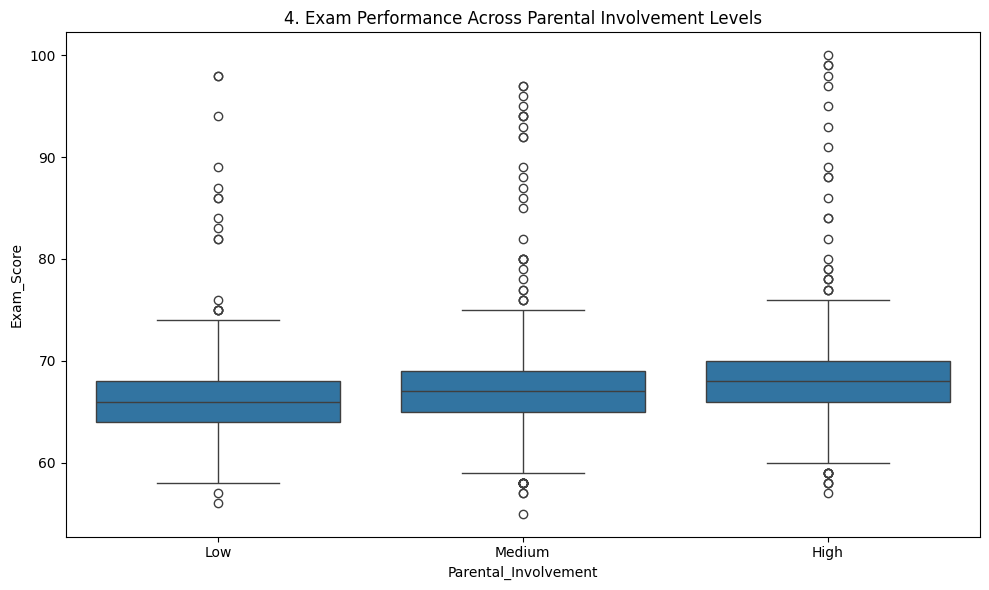

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Parental_Involvement', y='Exam_Score', order=['Low','Medium','High'])
plt.title(f'{plot_no}. Exam Performance Across Parental Involvement Levels')
show_fig()
plot_no += 1

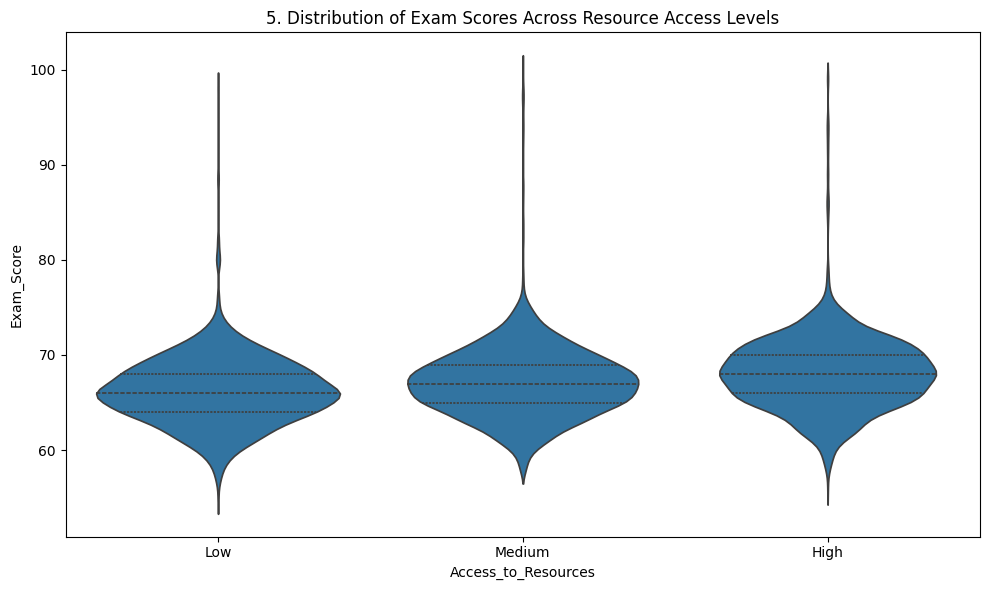

In [17]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='Access_to_Resources', y='Exam_Score', order=['Low','Medium','High'], inner='quartile')
plt.title(f'{plot_no}. Distribution of Exam Scores Across Resource Access Levels')
show_fig()
plot_no += 1

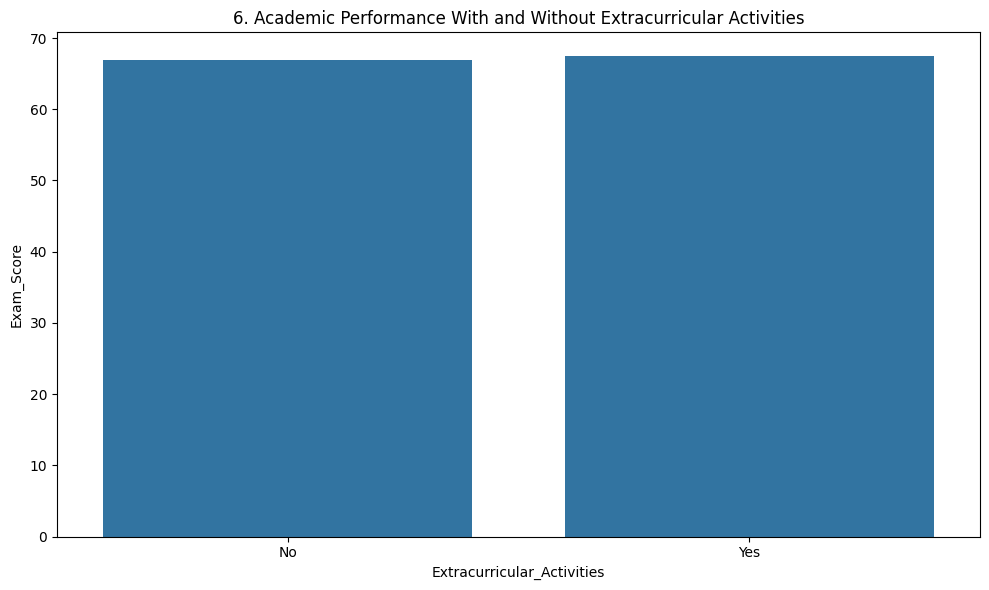

In [18]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Extracurricular_Activities', y='Exam_Score', errorbar=None)
plt.title(f'{plot_no}. Academic Performance With and Without Extracurricular Activities')
show_fig()
plot_no += 1

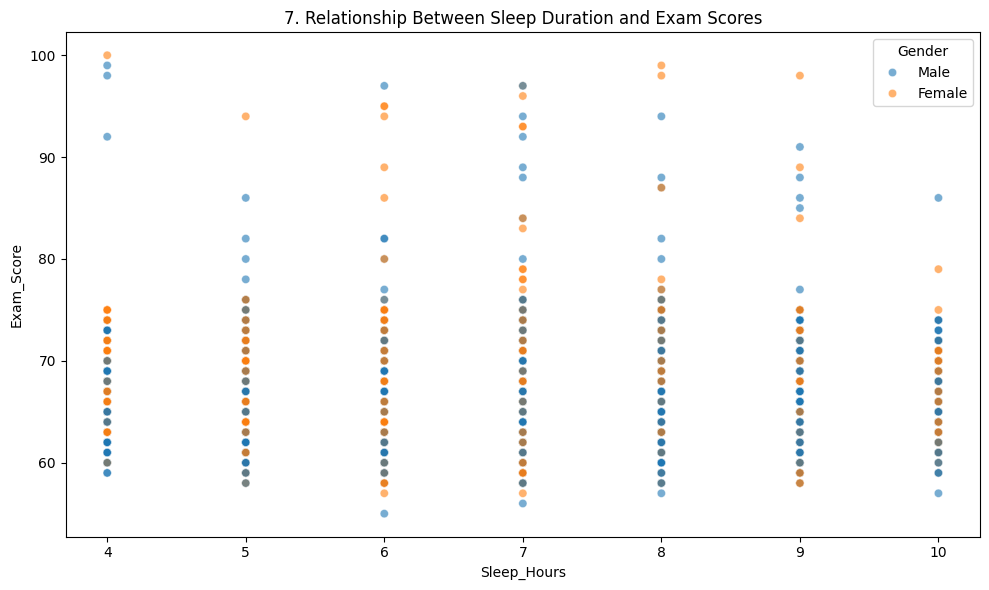

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Sleep_Hours', y='Exam_Score', hue='Gender', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Sleep Duration and Exam Scores')
show_fig()
plot_no += 1

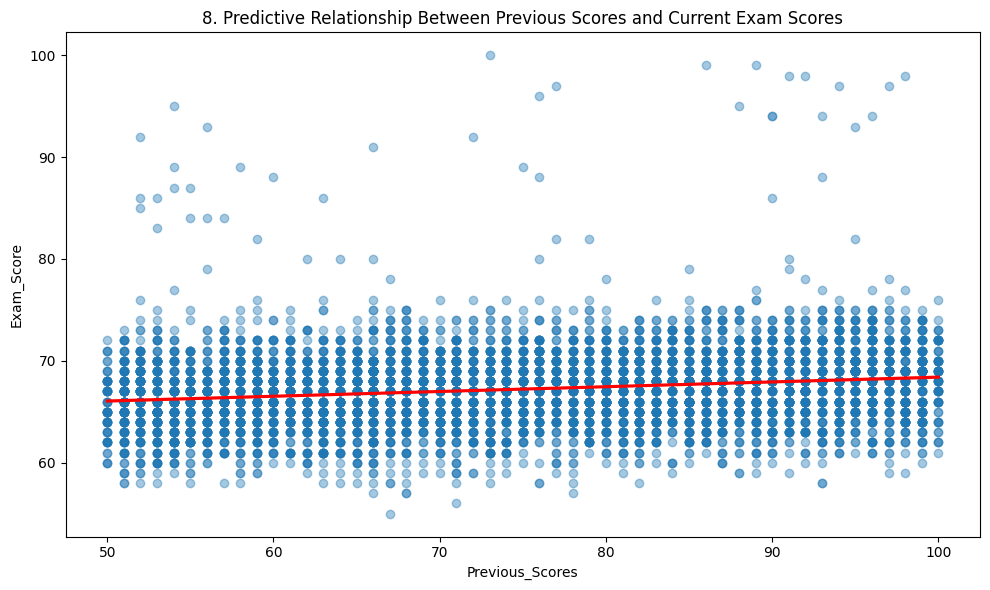

In [20]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='Previous_Scores', y='Exam_Score', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Predictive Relationship Between Previous Scores and Current Exam Scores')
show_fig()
plot_no += 1

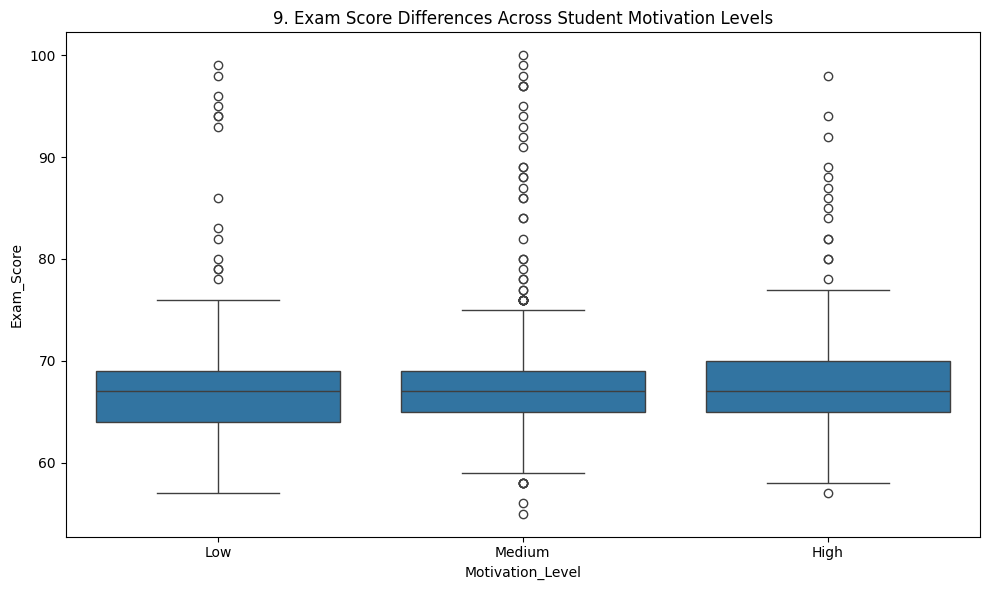

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Motivation_Level', y='Exam_Score', order=['Low','Medium','High'])
plt.title(f'{plot_no}. Exam Score Differences Across Student Motivation Levels')
show_fig()
plot_no += 1

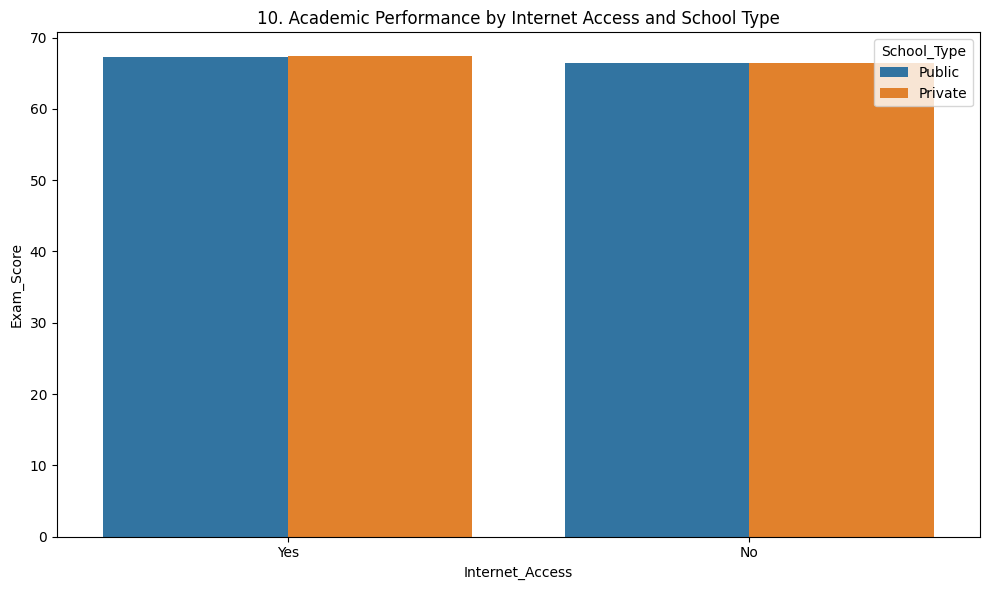

In [22]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Internet_Access', y='Exam_Score', hue='School_Type', errorbar=None)
plt.title(f'{plot_no}. Academic Performance by Internet Access and School Type')
show_fig()
plot_no += 1

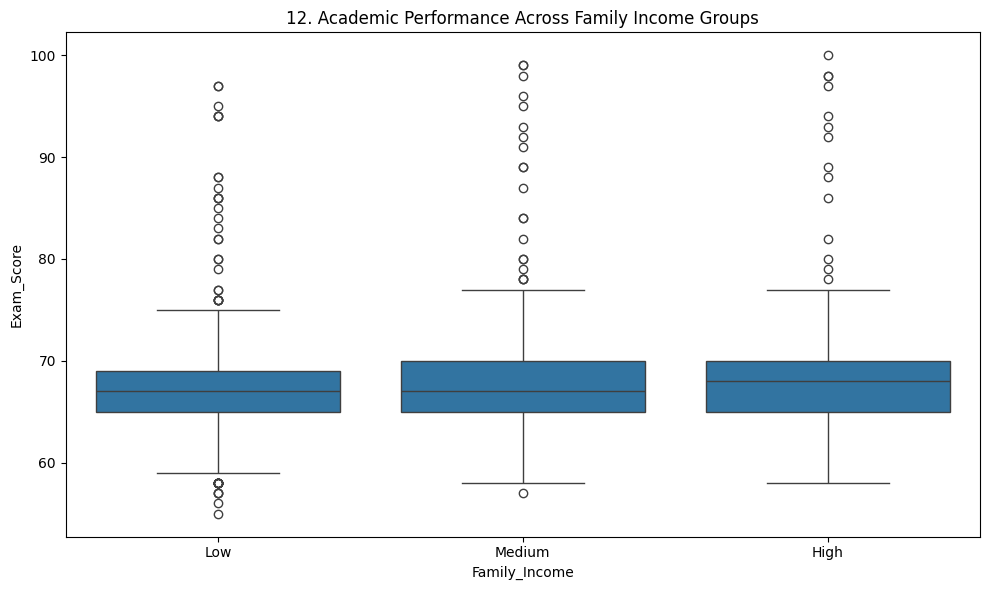

In [24]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Family_Income', y='Exam_Score', order=['Low','Medium','High'])
plt.title(f'{plot_no}. Academic Performance Across Family Income Groups')
show_fig()
plot_no += 1

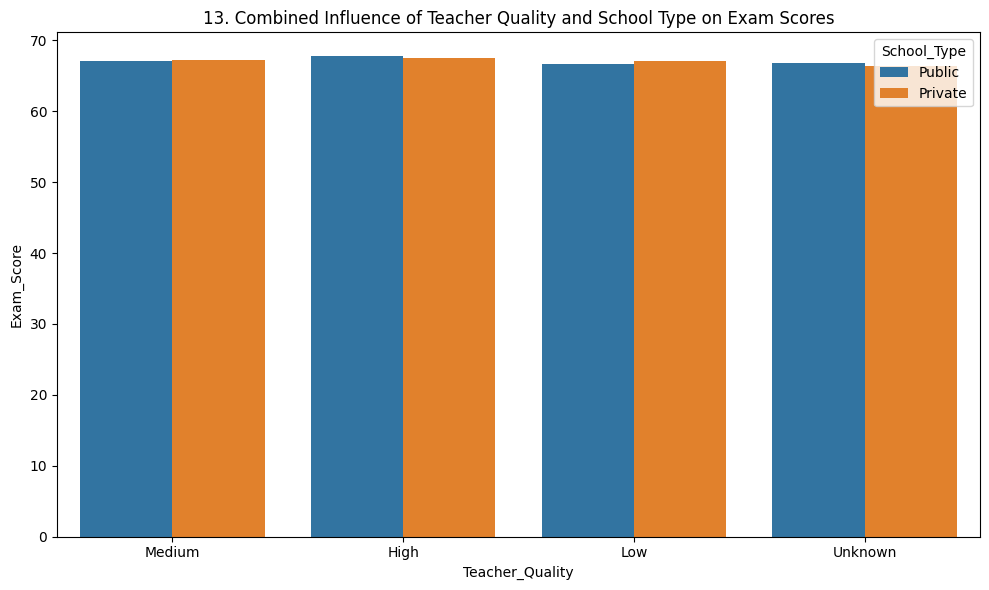

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Teacher_Quality', y='Exam_Score', hue='School_Type', errorbar=None)
plt.title(f'{plot_no}. Combined Influence of Teacher Quality and School Type on Exam Scores')
show_fig()
plot_no += 1

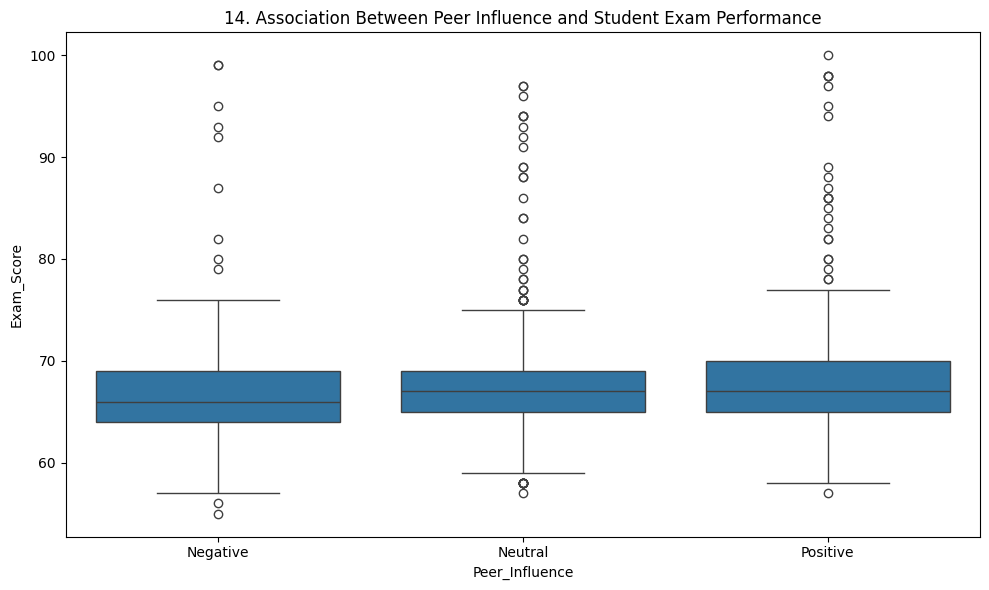

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Peer_Influence', y='Exam_Score', order=['Negative','Neutral','Positive'])
plt.title(f'{plot_no}. Association Between Peer Influence and Student Exam Performance')
show_fig()
plot_no += 1

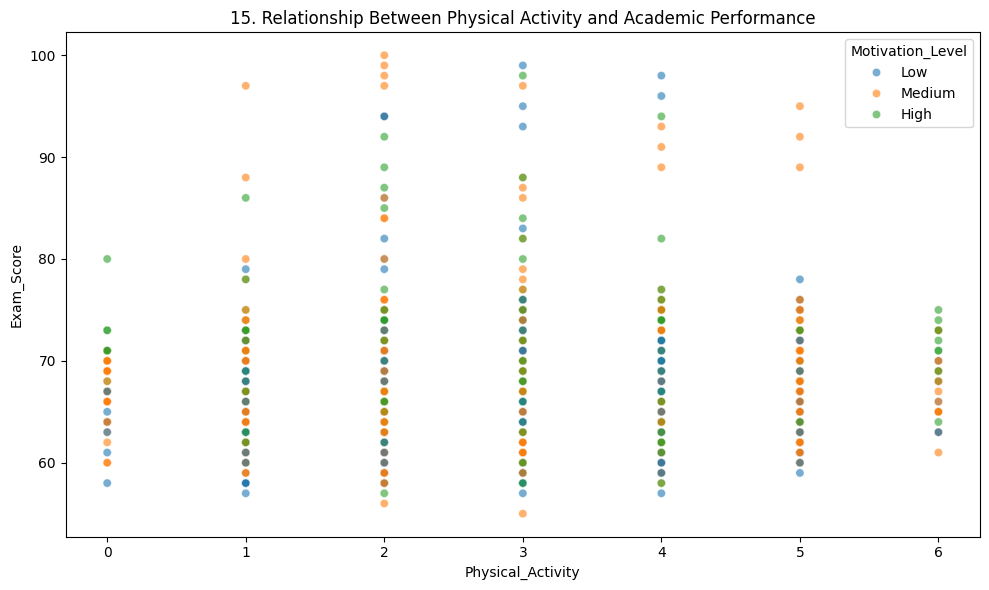

In [27]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Physical_Activity', y='Exam_Score', hue='Motivation_Level', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Physical Activity and Academic Performance')
show_fig()
plot_no += 1

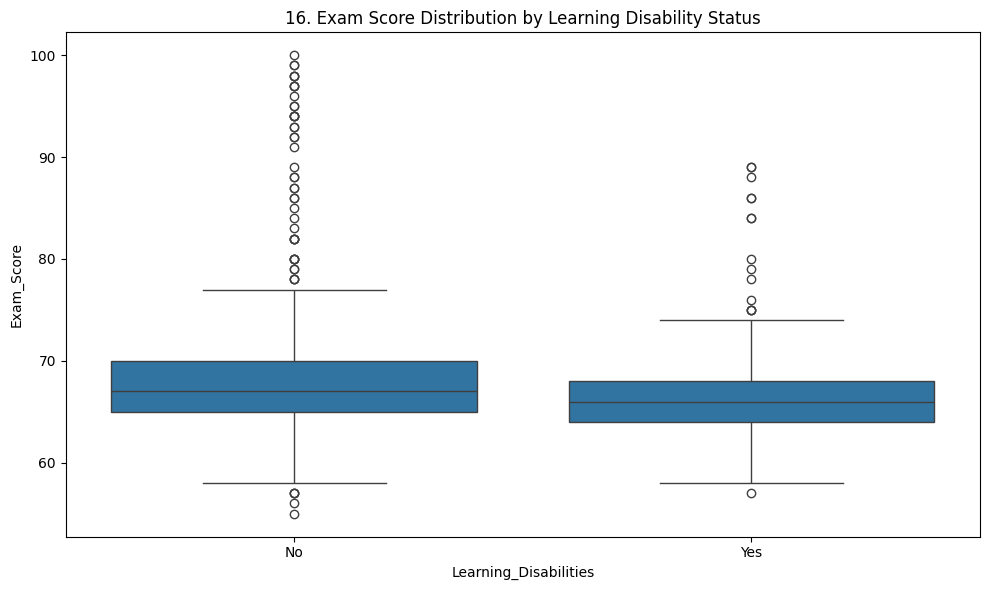

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Learning_Disabilities', y='Exam_Score')
plt.title(f'{plot_no}. Exam Score Distribution by Learning Disability Status')
show_fig()
plot_no += 1

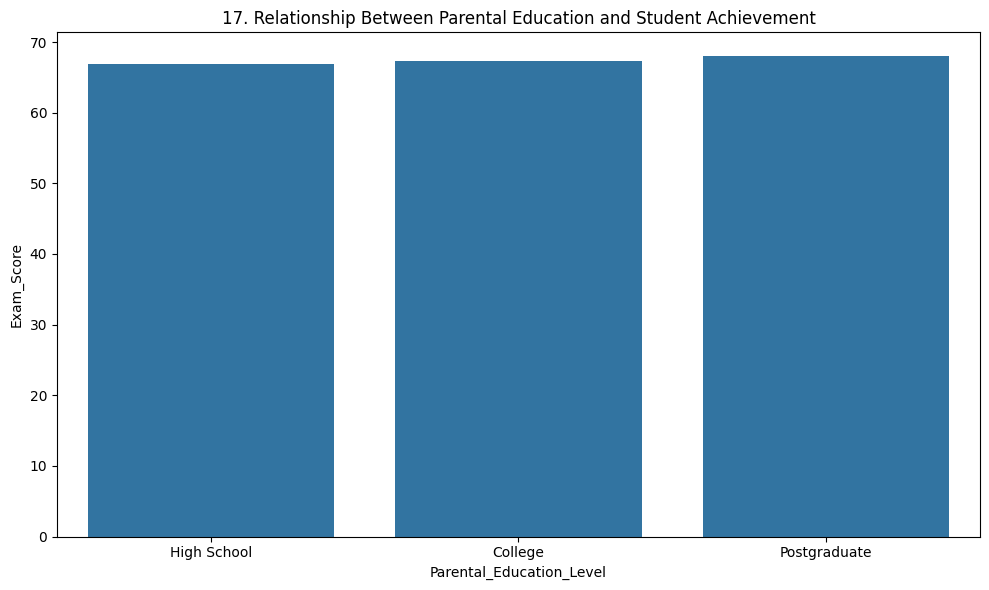

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Parental_Education_Level', y='Exam_Score', errorbar=None, order=['High School','College','Postgraduate'])
plt.title(f'{plot_no}. Relationship Between Parental Education and Student Achievement')
show_fig()
plot_no += 1

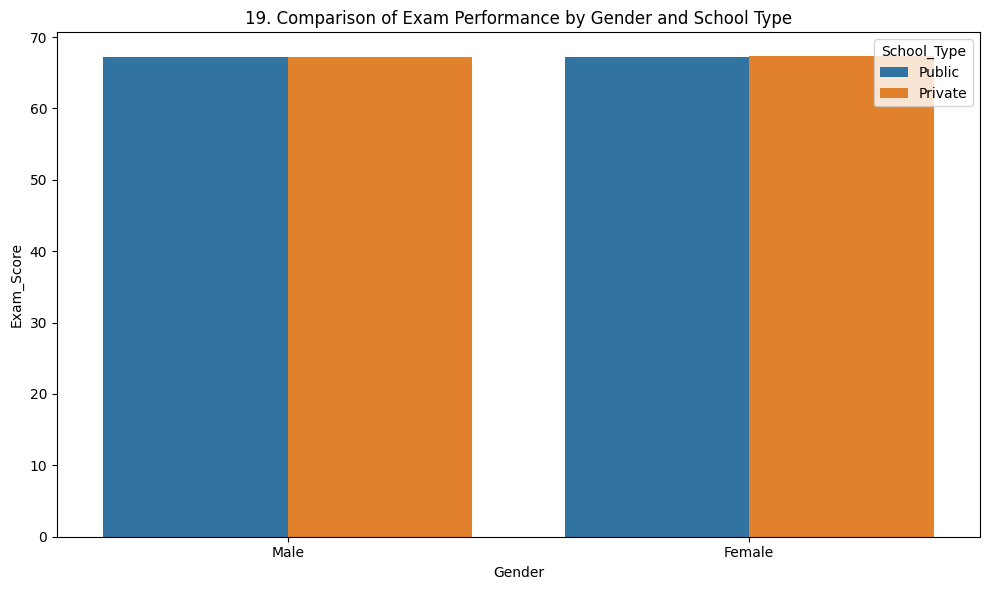

In [31]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='Gender', y='Exam_Score', hue='School_Type', errorbar=None)
plt.title(f'{plot_no}. Comparison of Exam Performance by Gender and School Type')
show_fig()
plot_no += 1

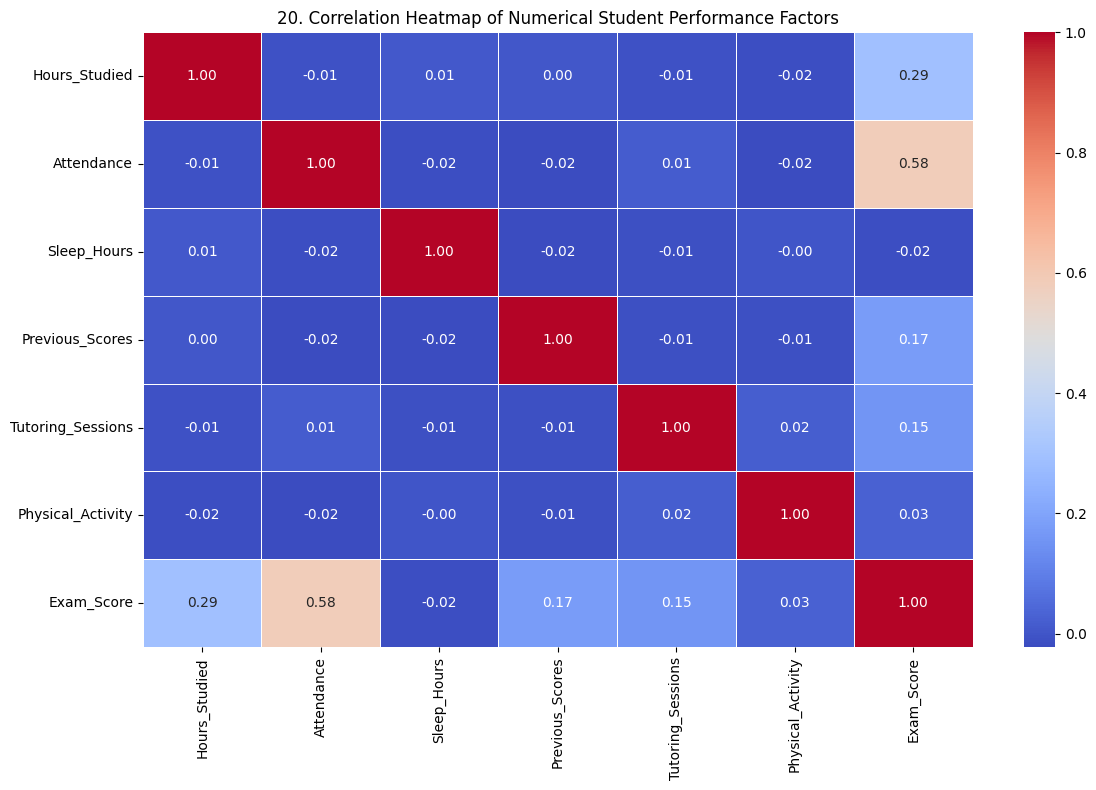

In [32]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Student Performance Factors')
show_fig()
plot_no += 1

# Model Training

## Separate features and target

In [33]:
X = df.drop(columns=['Exam_Score'])
y = df['Exam_Score']

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns
cat_cols = X.select_dtypes(exclude=np.number).columns

## Preprocess numerical and categorical features

In [35]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

## Create model pipeline

In [36]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=2,
        random_state=42
    ))
])

## Split dataset

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train model

In [38]:
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores',
       'Tutoring_Sessions', 'Physical_Activity'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most...
       'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access',
       'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence',
       'Learning_Disabilities', 'Parental_Education_Level',
       'Distance_from_Home', 'Gender'],
      dtype='object'))])),
                ('regressor',
                 HistGradientBoostingRegressor(l2_regularization=2,
                                               learning_rate=0.05, max_iter=300,
                                               max_leaf_nodes=20,
                                               random_state=42))])

## Make predictions

In [39]:
y_pred = model.predict(X_test)

## Evaluate model

In [40]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model: HistGradientBoostingRegressor")
print(f"R2 Score: {r2:.4f}")
print(f"Accuracy-like R2 Percentage: {r2*100:.2f}%")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

Model: HistGradientBoostingRegressor
R2 Score: 0.7037
Accuracy-like R2 Percentage: 70.37%
MAE: 0.9365
RMSE: 2.0467


## Actual vs predicted visualization

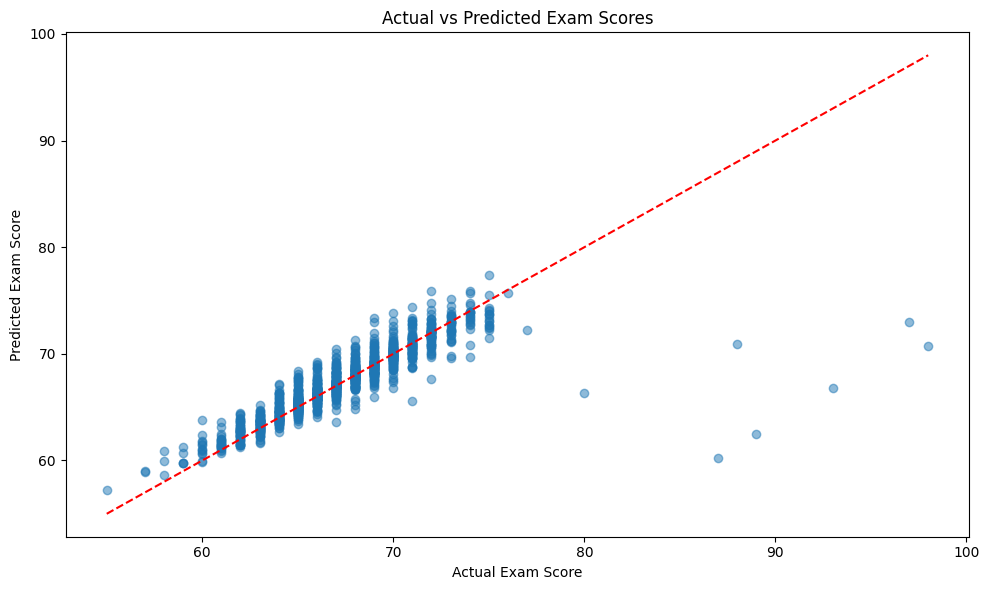

In [41]:
fig = plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual Exam Score')
plt.ylabel('Predicted Exam Score')
plt.title('Actual vs Predicted Exam Scores')
show_fig()